# Final fit and characterization of the selected structure

The selection ends with a final anchor (`reduction/final_anchor_state.pkl`): the structure (which parameters are free) and the fitted point. This notebook takes that structure through the **final analysis** (`final_analysis.run_final_analysis`) and reports it:

1. **Re-estimate.** The structure is re-solved from the anchor primal point with the tight warm start. The solved point is *accepted* if its objective is within a fraction of the likelihood-ratio threshold of the anchor,
$$ \text{obj}_\text{re-estimated} \;\le\; \text{obj}_\text{anchor} + 0.5\,\Delta_\text{LR}, \qquad \Delta_\text{LR} = \frac{\chi^2_{0.95,\,1}}{2N} = 0.0873 \;\;(N = 22), $$
(parmest's objective is $\frac1N\sum_e \tfrac12\chi^2_e$, so a $\Delta\chi^2$ of $c$ is $c/(2N)$ in the objective); otherwise the anchor primal is used for all point estimates. The accepted point is the `final/anchor_state.pkl` that the bootstrap, the profiles and the LOOCV start from.
2. **Final structural check** (rate level and output level) at the final point: classes `identifiable` / `bound_identified` / `non_identifiable`, and the parameters kept free by the protections (nuisance, `kept_free_by_rule`).
3. **Practical analysis on the Schur complement** of the nuisance parameters: rank at the eigenvalue cut, singular spectrum, correlations, CV per parameter (the CVs come from the pseudo-inverse of the FIM and are only indicative).
4. **Covariance cross-check** with the k_aug covariance of the extensive form (a forked child with a timeout; no fallback, so it is skipped if the point was not re-estimated).
5. **Fit metrics**: objective breakdown per condition, in-sample prediction at the fitted primal point (RMSE and $R^2$ against the per-output mean, and against the training-mean baseline), drains against the data.

The misfit scale $s^2 = 2N\,\text{obj}/(n_\text{outputs} - p)$ (residual $\chi^2$ per degree of freedom) rescales the LR threshold when the model misses by more than the measurement error. Section 7 of this notebook writes `REPORT.md`.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import final_analysis
from report import build_report
from settings import THRESHOLDS, RUN as RUN_SETTINGS, default_params
from metrics import lr_threshold, pred_metrics

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)

N_JOBS = int(os.environ.get("HK_N_JOBS", RUN_SETTINGS["n_jobs"]))
RED = os.path.join(OUT, "reduction")
FINAL = os.path.join(OUT, "final")

def read_optional(path, **kw):
    """pd.read_csv, or None with a message if the file is not there (e.g. an output only a newer run writes)."""
    if os.path.exists(path):
        return pd.read_csv(path, **kw)
    print("not found (written by a later step or a newer run?): " + os.path.relpath(path, OUT))
    return None

def read_json(path):
    """json file as a dict, or None with a message."""
    if os.path.exists(path):
        return json.load(open(path))
    print("not found (written by a later step or a newer run?): " + os.path.relpath(path, OUT))
    return None

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : False (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. Run (`HK_RUN=1`)

Reads `OUT/reduction` (`final_anchor_state.pkl`, `fixing_log.csv`, `reduction_summary.json`) and writes `OUT/final/`. The long part is the k_aug covariance and the reduced sensitivities of the final structure (a few minutes). Switch: `HK_N_JOBS`; the settings are the dict `params` below (defaults from `settings/thresholds.csv`).

In [2]:
# Settings of the final analysis (defaults from settings/thresholds.csv)
params = default_params("final")
params["final_accept_lr_fraction"] = 0.5   # the re-estimate is used if obj <= obj_anchor + this x the LR threshold
params["lr_alpha"] = 0.95                  # level of the likelihood-ratio threshold
params["n_jobs"] = N_JOBS                  # worker processes (HK_N_JOBS)
params

{'n_jobs': 8,
 'lr_alpha': 0.95,
 'final_accept_lr_fraction': 0.5,
 'theta_at_bound_tol': 0.01,
 'sens_step': 0.01,
 'sens_step_check': 0.003,
 'fd_consistency_rtol': 0.1,
 'fd_consistency_atol': 0.001,
 'corr_threshold': 0.9,
 'zero_cut': 1e-06,
 'eig_cut': 1e-08,
 'structural_q': 10,
 'structural_q_out': 5,
 'seed_base': 1000,
 'final_seed_base': 9000,
 'perturb_seed_offset': 5000,
 'structural_sv_tol': 1e-10,
 'structural_guard_rel': 1e-06,
 'structural_load_min': 0.05,
 'tie_rtol': 0.25,
 'realization_lo': 0.5,
 'realization_hi': 1.5,
 'perturb_lo': 0.5,
 'perturb_hi': 2.0,
 'output_realization_lo': 0.5,
 'output_realization_hi': 2.0,
 'output_perturb_lo': 0.5,
 'output_perturb_hi': 2.0,
 'active_rtol': 0.0001,
 'rank_rcond': 1e-10}

In [3]:
if RUN:
    summary = final_analysis.run_final_analysis(OUT, params)
    print("final point: %s, obj %.5f, %d free" % (summary["final_point"], summary["obj"], summary["n_free"]))
else:
    print("RUN is False: the final analysis is loaded from", FINAL)

RUN is False: the final analysis is loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model/final


## 2. Summary of the final point

`final_summary.json` collects the numbers of the final analysis.

In [4]:
summary = read_json(os.path.join(FINAL, "final_summary.json"))
if summary is not None:
    keys = ["final_point", "obj_anchor", "obj_re_estimated", "re_estimate_acceptance_limit", "n_free", "obj", "s2",
            "n_analysed", "kept_free_by_rule", "eig_cut", "rank_at_cut", "full_rank", "sigma_ratio", "cond_F", "max_abs_r",
            "n_pairs_gt_0.9", "flagged", "flags", "reduction_status", "lr_threshold_0.95", "lr_threshold_0.95_s2", "output_level",
            "cov_method", "cov_psd", "rmse_met", "rmse_met_meanbaseline", "r2_met_permean", "rmse_flux_li",
            "rmse_flux_li_meanbaseline", "r2_flux_li_permean", "b_rmse_vs_data", "n_drains_at_bound", "n_drain_values",
            "theta_at_bounds"]
    display(pd.Series({k: str(summary[k]) for k in keys if k in summary}, name="value").to_frame())

,value
final_point,re_estimated
obj_anchor,10.920253495386847
obj_re_estimated,10.942882817435018
re_estimate_acceptance_limit,10.963906436531099
n_free,11
obj,10.942882817435018
s2,2.383598237461093
n_analysed,7
kept_free_by_rule,"['K_g6p_1', 'kcat_f_3', 'kcat_f_6', 'kcat_f_7']"
eig_cut,1e-08


The LR thresholds of the summary follow from `metrics.lr_threshold`: $\chi^2_{0.95,1}/(2N)$, optionally times $s^2$.

In [5]:
n_conditions = 22
print("lr_threshold(0.95, %d)        = %.4f" % (n_conditions, lr_threshold(THRESHOLDS["lr_alpha"], n_conditions)))
if summary is not None:
    print("lr_threshold(0.95, %d, s2=%.2f) = %.4f" % (n_conditions, summary["s2"], lr_threshold(THRESHOLDS["lr_alpha"], n_conditions, s2=summary["s2"])))

lr_threshold(0.95, 22)        = 0.0873
lr_threshold(0.95, 22, s2=2.38) = 0.2081


## 3. The final structure

`final_structure.csv` has the 37 parameters: for the free ones the class, the flags, the influence and the CV from the Schur complement (`cv_basis` is `schur`, or `nuisance_conditional` for the nuisance parameters, whose CV is conditional and bound driven), for the fixed ones the iteration and the rule that fixed them.

* `identifiable`: the output-level test finds no null direction (also with the active set) and the parameter is not flagged;
* `bound_identified`: identifiable only because a free variable sits on a bound;
* `non_identifiable`: absorbed by free cofactors / drains / unmeasured states; only kept because the protections forbid fixing it (then `kept_free_by_rule`);
* `flagged`: at a theta bound or with unstable finite differences; never reported as identifiable.

In [6]:
final_structure = read_optional(os.path.join(FINAL, "final_structure.csv"))
if final_structure is not None:
    cols = ["param", "status", "value", "ident_class", "output_class", "flags", "influence", "cv_percent", "cv_basis",
            "fixed_iter", "fixed_rule"]
    fs = final_structure[[c for c in cols if c in final_structure.columns]].set_index("param")
    display(fs[fs["status"] == "free"].drop(columns=["status", "fixed_iter", "fixed_rule"], errors="ignore"))
    display(fs[fs["status"] == "fixed"][["value", "fixed_iter", "fixed_rule"]])

,value,ident_class,output_class,flags,influence,cv_percent,cv_basis
param,,,,,,,
K_g6p_1,10.001076,kept_free_by_rule,non_identifiable,fd_unstable,0.003307,2625.816520,nuisance_conditional
Ks_g6p_pgi,0.197194,identifiable,identifiable,NaN,0.014963,854.258055,schur
kcat_f_2,917.423639,identifiable,identifiable,NaN,0.058584,212.138947,schur
kcat_f_3,960.087926,kept_free_by_rule,bound_identified,NaN,0.628366,11.295563,nuisance_conditional
Ks_fbp_4,0.001002,flagged,identifiable,at_bound,0.083369,139.220965,schur
kcat_f_4,2.699551,identifiable,identifiable,NaN,2.017004,5.684563,schur
kcat_f_5,5578.920937,flagged,identifiable,fd_unstable,0.004833,2625.433332,schur
kcat_f_6,537.757240,kept_free_by_rule,non_identifiable,fd_unstable,0.006173,1356.241079,nuisance_conditional
kcat_f_7,720.523954,kept_free_by_rule,non_identifiable,NaN,0.008929,858.636751,nuisance_conditional


,value,fixed_iter,fixed_rule
param,,,
v_max_1,80.209416,0.0,structural_output
Ka1_1,0.094564,0.0,structural_output
Ka2_1,0.975483,0.0,structural_output
Ka3_1,0.731318,0.0,structural_output
Kp_f6p_pgi,10.371590,3.0,svd
Ks_f6p_3,3.579306,0.0,structural_output
Ks_atp_3,0.001972,0.0,structural_exact
Kp_fbp_3,0.007364,0.0,structural_output
Kp_adp_3,0.002101,0.0,structural_exact


### Practical analysis: spectrum and correlations

The singular spectrum of the Schur complement (`final_singular_spectrum.csv`, eigenvalue ratios against the cut $10^{-8}$) and the correlation matrix from its pseudo-inverse (`final_correlation.csv`). Full rank and $\max|r| < 0.9$ is the convergence criterion of the selection; a high CV with full rank only says the information is small.

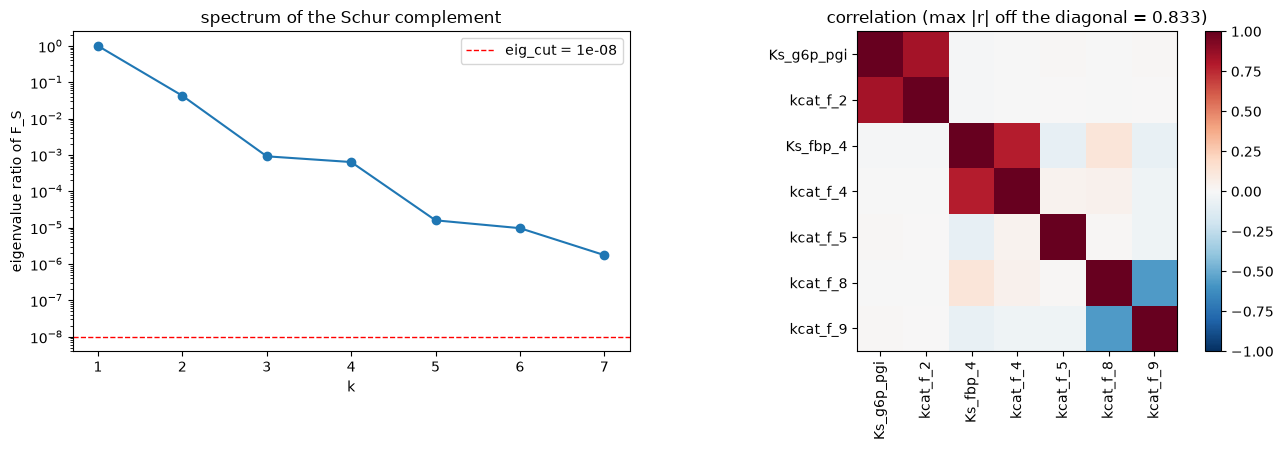

In [7]:
spectrum = read_optional(os.path.join(FINAL, "final_singular_spectrum.csv"), index_col=0)
corr = read_optional(os.path.join(FINAL, "final_correlation.csv"), index_col=0)

if spectrum is not None and corr is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    ax_spec, ax_corr = axes

    ax_spec.semilogy(spectrum.index + 1, spectrum["eig_ratio"], "o-")
    ax_spec.axhline(THRESHOLDS["eig_cut"], color="red", ls="--", lw=1, label="eig_cut = %.0e" % THRESHOLDS["eig_cut"])
    ax_spec.set_xlabel("k")
    ax_spec.set_ylabel("eigenvalue ratio of F_S")
    ax_spec.legend()
    ax_spec.set_title("spectrum of the Schur complement")

    im = ax_corr.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax_corr.set_xticks(range(len(corr)))
    ax_corr.set_xticklabels(corr.columns, rotation=90)
    ax_corr.set_yticks(range(len(corr)))
    ax_corr.set_yticklabels(corr.index)
    fig.colorbar(im, ax=ax_corr, fraction=0.045)
    ax_corr.set_title("correlation (max |r| off the diagonal = %.3f)" % (np.abs(corr.to_numpy() - np.eye(len(corr))).max()))

    fig.tight_layout()
    plt.show()

### Covariance cross-check

`sd_schur` is the standard deviation from the Schur-complement FIM, `sd_schur_s2scaled` the same times $s$; `sd_kaug` comes from the k_aug covariance of the extensive form. The two agree only to within a factor of a few and not at all for the parameters the data cannot move (K_g6p_1), which is why the CVs are only indicative and the bootstrap and profiles are the uncertainty quantification.

In [8]:
cross = read_optional(os.path.join(FINAL, "covariance_crosscheck.csv"), index_col=0)
cross

,sd_schur,sd_schur_s2scaled,var_kaug,sd_kaug,cv_percent_kaug,ratio_kaug_over_schur_s2
param,,,,,,
K_g6p_1,262.609893,405.440950,2.034723e+14,1.426437e+07,1.426284e+08,35182.364773
Ks_g6p_pgi,1.684543,2.600750,3.188371e+00,1.785601e+00,9.055061e+02,0.686571
kcat_f_2,1946.212851,3004.739759,1.207817e+07,3.475365e+03,3.788180e+02,1.156628
kcat_f_3,108.447337,167.430825,1.015523e+05,3.186728e+02,3.319204e+01,1.903310
Ks_fbp_4,0.001395,0.002154,2.691121e-05,5.187601e-03,5.176073e+02,2.408126
kcat_f_4,0.153458,0.236922,1.025884e+00,1.012859e+00,3.751955e+01,4.275078
kcat_f_5,146470.849844,226134.970748,2.196879e+09,4.687087e+04,8.401423e+02,0.207269
kcat_f_6,7293.284599,11260.033661,1.982310e+08,1.407945e+04,2.618180e+03,1.250392
kcat_f_7,6186.683464,9551.562550,1.863352e+07,4.316656e+03,5.990996e+02,0.451932


## 4. Fit metrics

**Objective per condition.** `objective_breakdown.csv` solves each condition with the kinetic parameters fixed at the final values (inner problem over $x,u,b$): the sum of the flux and metabolite weighted SSE per condition. KO18 and KO05 carry most of the objective; they are also the conditions that dominate the bootstrap objective.

mean over conditions (= the estimator objective): 10.9363


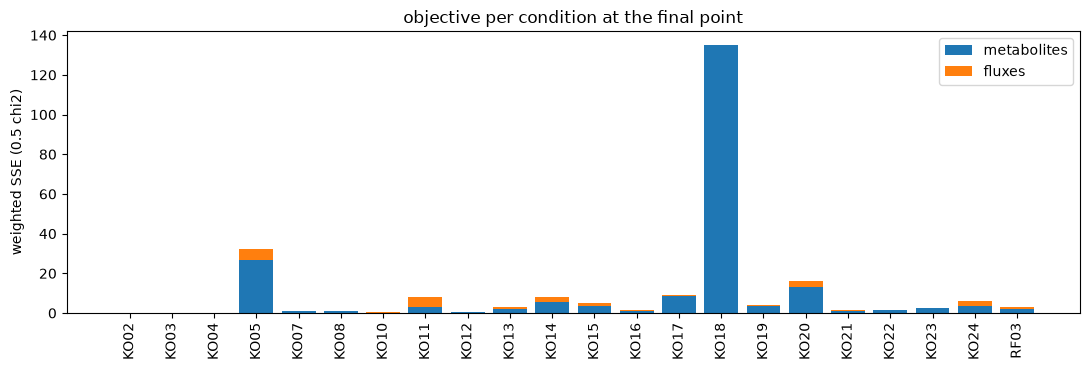

In [9]:
breakdown = read_optional(os.path.join(FINAL, "objective_breakdown.csv"), index_col=0)
if breakdown is not None:
    per_cond = breakdown.drop(index=[i for i in ("TOTAL", "MEAN") if i in breakdown.index])
    print("mean over conditions (= the estimator objective): %.4f" % breakdown.loc["MEAN", "total"])

    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.bar(range(len(per_cond)), per_cond["met_wsse"], color="tab:blue", label="metabolites")
    ax.bar(range(len(per_cond)), per_cond["flux_wsse"], bottom=per_cond["met_wsse"], color="tab:orange", label="fluxes")
    ax.set_xticks(range(len(per_cond)))
    ax.set_xticklabels(per_cond.index, rotation=90)
    ax.set_ylabel("weighted SSE (0.5 chi2)")
    ax.set_title("objective per condition at the final point")
    ax.legend()
    fig.tight_layout()
    plt.show()

**Prediction metrics.** `pred_insample_predicted.csv` / `pred_insample_real.csv` are the predictions at the fitted primal point (not a re-simulation from an arbitrary start). `metrics.pred_metrics` gives RMSE and $R^2$ over the measured cells; $R^2$ is reported against the per-output mean (stricter than the pooled $R^2$) and the RMSE of the mean predictor is the baseline.

In [10]:
predicted = read_optional(os.path.join(FINAL, "pred_insample_predicted.csv"), index_col=0)
real = read_optional(os.path.join(FINAL, "pred_insample_real.csv"), index_col=0)
if predicted is not None and real is not None:
    pm = pred_metrics(real.loc[predicted.index, predicted.columns], predicted)
    table = pd.DataFrame({"model": [pm["rmse_met"], pm["rmse_flux_li"]],
                          "mean baseline": [pm["rmse_met_meanbaseline"], pm["rmse_flux_li_meanbaseline"]],
                          "R2 per-output mean": [pm["r2_met_permean"], pm["r2_flux_li_permean"]],
                          "R2 pooled": [pm["r2_met_pooled"], pm["r2_flux_li_pooled"]],
                          "n": [pm["n_met"], pm["n_flux_li"]]}, index=["RMSE metabolites (mM)", "RMSE LI fluxes"])
    display(table)

,model,mean baseline,R2 per-output mean,R2 pooled,n
RMSE metabolites (mM),0.115092,0.157566,0.466460,0.641069,103
RMSE LI fluxes,0.359586,0.727047,0.755387,0.937754,110


**Free drains against the data.** The drains $b = S v$ of g6p, f6p, g3p, 3pg and pep are free decision variables bounded by the data range plus 10% of the span; a drain at a bound is a sign that the model would like to leave the box.

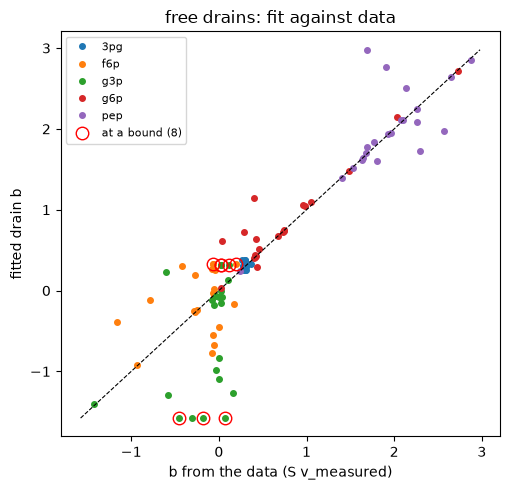

RMSE of the drains: 0.448, 8 of 110 values at a bound


In [11]:
drains = read_optional(os.path.join(FINAL, "b_fit_vs_data.csv"))
if drains is not None:
    fig, ax = plt.subplots(figsize=(5.2, 5))
    for key, grp in drains.groupby("key"):
        ax.plot(grp["b_data"], grp["b_fit"], "o", ms=4, label=key[2:])
    at_b = drains[drains["at_bound"]]
    ax.plot(at_b["b_data"], at_b["b_fit"], "o", mfc="none", mec="red", ms=9, label="at a bound (%d)" % len(at_b))
    lims = [drains[["b_data", "b_fit"]].min().min(), drains[["b_data", "b_fit"]].max().max()]
    ax.plot(lims, lims, "k--", lw=0.8)
    ax.set_xlabel("b from the data (S v_measured)")
    ax.set_ylabel("fitted drain b")
    ax.legend(fontsize=8)
    ax.set_title("free drains: fit against data")
    fig.tight_layout()
    plt.show()
    print("RMSE of the drains: %.3f, %d of %d values at a bound" % (np.sqrt(np.mean(drains["err"] ** 2)), int(drains["at_bound"].sum()), len(drains)))

## 5. Output-level classes at the final point

`output_level_classes.csv`: the class of every free parameter in the bound-free output-level test. `final_structural_check.csv` is the row of the final structural check (null dimensions at the rate and output level, kept free by the protections).

In [12]:
classes = read_optional(os.path.join(FINAL, "output_level_classes.csv"))
check = read_optional(os.path.join(FINAL, "final_structural_check.csv"), index_col=0)
if classes is not None:
    display(classes.set_index("param").T)

if check is not None:
    display(check.loc[[i for i in ("n_free", "null_dim_consensus", "out_null_dim", "out_null_dim_active_set", "out_n_identifiable",
                                   "out_n_bound_identified", "out_n_non_identifiable", "kept_free_by_rule") if i in check.index]])

param,K_g6p_1,Ks_g6p_pgi,kcat_f_2,kcat_f_3,Ks_fbp_4,kcat_f_4,kcat_f_5,kcat_f_6,kcat_f_7,kcat_f_8,kcat_f_9
output_class,non_identifiable,identifiable,identifiable,bound_identified,identifiable,identifiable,identifiable,non_identifiable,non_identifiable,identifiable,identifiable


,value
n_free,11
null_dim_consensus,0
out_null_dim,4
out_null_dim_active_set,3
out_n_identifiable,7
out_n_bound_identified,1
out_n_non_identifiable,3
kept_free_by_rule,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7


## 6. The fixing log with classes

`reduction/fixing_log.csv` joined with the output-level class at the time of each output-level fix (`fixing_log_with_classes.csv` is saved by `parameter_selection.ipynb`).

In [13]:
fix_log = read_optional(os.path.join(RED, "fixing_log.csv"))
fix_cls = None
if os.path.exists(os.path.join(OUT, "fixing_log_with_classes.csv")):
    fix_cls = pd.read_csv(os.path.join(OUT, "fixing_log_with_classes.csv"))
elif fix_log is not None:
    fix_cls = fix_log.copy()
    if "output_class_at_fix" in fix_cls.columns:
        fix_cls["class_at_fix"] = fix_cls["output_class_at_fix"]

if fix_cls is not None:
    display(fix_cls[[c for c in ("param", "iter", "rule", "influence_param", "class_at_fix") if c in fix_cls.columns]])

,param,iter,rule,influence_param,class_at_fix
0,Ks_atp_3,0,structural_exact,6.865369e-01,non_identifiable
1,Kp_adp_3,0,structural_exact,6.863315e-01,non_identifiable
2,Kp_g3p_4,0,structural_exact,1.610152e-06,non_identifiable
3,Ks_g3p_6,0,structural_exact,5.977163e-04,non_identifiable
4,Ks_nad_6,0,structural_exact,5.977151e-04,non_identifiable
5,Kp_nadh_6,0,structural_exact,5.637182e-07,non_identifiable
6,Ks_pgp_7,0,structural_exact,2.779808e-03,non_identifiable
7,Ks_3pg_7,0,structural_exact,1.603780e-05,non_identifiable
8,Kp_pgp_6,0,structural_pointdep,2.875369e-06,non_identifiable
9,v_max_1,0,structural_output,1.989346e-03,non_identifiable


## 7. REPORT.md

`report.build_report` assembles the report from the saved files of every step: final analysis, bootstrap, profiles, LOOCV. Steps that have not run yet are marked "not run" in the report, so **re-run this section (no `HK_RUN` needed) after `bootstrap.ipynb`, `profiles.ipynb` and `loocv.ipynb`** to complete it. The Fit section compares the final fit with the previous run named in `settings/run.csv` (`compare_to`, `results_v3/flux_model`); when that folder is not in the checkout the comparison is left out ("reference run not found"). Everything in the text (counts, parameter names, thresholds, the list of `above_bound` folds, the figures present in `OUT/figures`) is computed from the saved files. It is written to `OUT/REPORT.md` unless `OUT` is one of the frozen result folders.

In [14]:
report_text = build_report(OUT)
if WRITABLE:
    with open(os.path.join(OUT, "REPORT.md"), "w") as fh:
        fh.write(report_text)
    print("REPORT.md written to", OUT, "(%d lines)" % report_text.count("\n"))
else:
    print("OUT is a frozen result folder: REPORT.md not written")

print(report_text[:3000])

REPORT.md written to /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model (126 lines)
# Flux model, repaired pipeline (results_v4/flux_model)

## Identifiability first
Final structure: 11 free / 26 fixed, reduction status `converged`; final point = re_estimated (obj 10.9429; reduction anchor 10.9203; acceptance limit 10.9639).
Practical criteria on the Schur complement (4 kept_free_by_rule parameters as nuisance): rank 7/7 at eigenvalue cut 1e-08 (singular ratio 1e-4), max |r| 0.833, no |r|>0.9 pair. Output-level classes (bound-free / active set): {'identifiable': 7, 'bound_identified': 1, 'non_identifiable': 3}.
Flags: {'K_g6p_1': ['fd_unstable'], 'Ks_fbp_4': ['at_bound'], 'kcat_f_5': ['fd_unstable'], 'kcat_f_6': ['fd_unstable']}.
```
     param       ident_class     output_class       flags     value  influence  cv_percent             cv_basis  bootstrap_cv_%  boot_ci_ratio profile_class
   K_g6p_1 kept_free_by_rule non_identifiable fd_unstable   10.0011     0.0033